# **APS 2 — Inteligência Artificial Aplicada: Canteiro de Obras Inteligente "Torre Europarque"**
### *Sistemas Inteligentes de Otimização, Conhecimento, Redes Neurais e Lógica Fuzzy na Construção Civil*

* **Instituição:** Centro Universitário UniSENAI PR — Campus Londrina
* **Curso:** Engenharia de Software | 6º Período (2026/2)
* **Disciplina:** Inteligência Artificial Aplicada
* **Docente:** Prof. Paulo Cesar Dias Lima

**Integrantes do Grupo:**

* Felipy Yuske Ogido — RA: `[inserir RA]`
* Fernando Junior Vaciski de Camargo — RA: `[inserir RA]`
* Giovana Nunes Constancio Donato — RA: `01033251`
* Graciele Miki Sazaka — RA: `[inserir RA]`
* João Paulo Simplicio — RA: `[inserir RA]`

*(Representante do Grupo: `A DEFINIR`)*


In [1]:
# ==============================================================================
# CONFIGURAÇÃO DO AMBIENTE E IMPORTS GLOBAIS (TODAS AS ETAPAS)
# ==============================================================================

# Instalação das bibliotecas necessárias no Google Colab
# (PuLP fixado na série 2.x: a versão 4.x mudou a API e quebra pulp.LpVariable(lowBound=...))
!pip install -q "pulp<3" deap simpy rdflib scikit-fuzzy tabulate

# Base, manipulação de dados e visualização
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Etapa 1 — Busca Heurística (A*) e Programação Linear
import networkx as nx
import pulp

# Etapa 2 — Algoritmo Genético (VRP) e Simulação Discreta
from deap import base, creator, tools, algorithms
import simpy

# Etapa 3 — Ontologia RDF/OWL e SPARQL
from rdflib import Graph, Namespace, Literal, URIRef
from rdflib.namespace import RDF, RDFS, OWL, XSD

# Etapa 5 — Lógica Fuzzy
import skfuzzy as fuzz
from skfuzzy import control as ctrl

# Configurações globais de gráficos e pastas de saída
os.makedirs("outputs/graficos", exist_ok=True)
os.makedirs("outputs/tabelas", exist_ok=True)
plt.rcParams["figure.dpi"] = 120

# Semente global para reprodutibilidade (GA, SimPy, MLP)
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

print("Ambiente configurado com sucesso!")

Ambiente configurado com sucesso!


## Etapa 1 — Roteirização (A* em NetworkX) e Alocação de Recursos (PuLP)

### 1a — Busca Heurística A* (Malha 8x8)
O canteiro é modelado como uma malha ortogonal 8x8 (`nx.grid_2d_graph`), com movimentos em 4 direções e custo unitário por passo. Os obstáculos rígidos (andaimes e escavação) em **(3,3)** e **(3,4)** são removidos do grafo. O AGV parte do **Almoxarifado Central (0,0)** até a **Torre de Elevação (7,7)**, e o A* usa a **distância de Manhattan** como heurística h(n), que é admissível nesse tipo de malha (nunca superestima o custo real).

Origem (Almoxarifado Central): (0, 0)
Destino (Torre de Elevação):   (7, 7)
Obstáculos removidos:          [(3, 3), (3, 4)]
Custo total (passos):          14
Caminho ótimo encontrado:
[(0, 0), (1, 0), (2, 0), (3, 0), (4, 0), (5, 0), (6, 0), (7, 0), (7, 1), (7, 2), (7, 3), (7, 4), (7, 5), (7, 6), (7, 7)]

h(início) = 14 passos (limite inferior da heurística)
Caminhos ótimos empatados — sem obstáculos: 3432 | com obstáculos: 1507


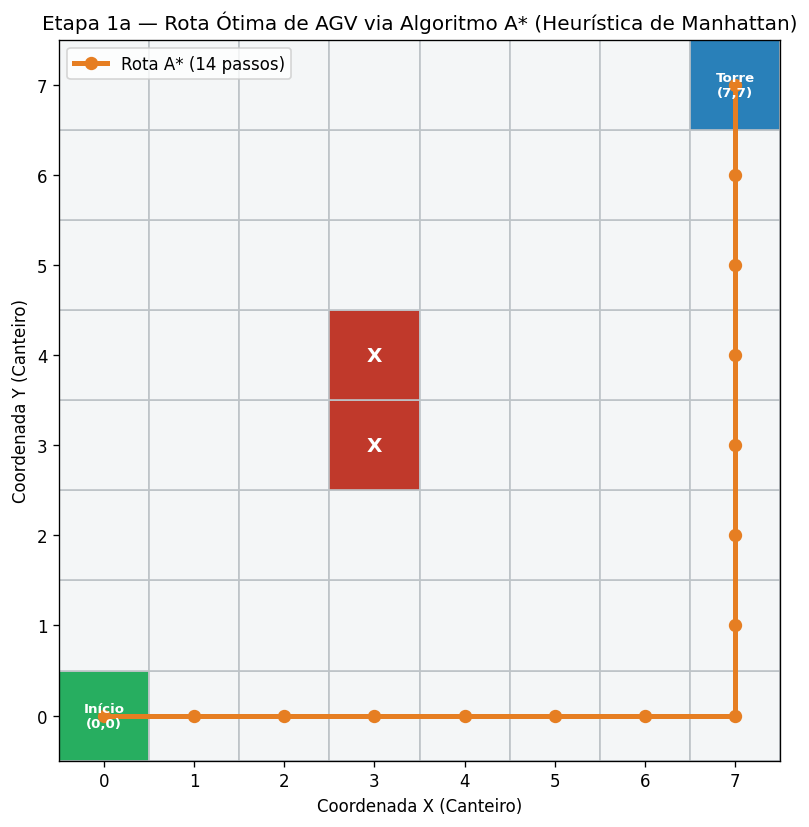

In [2]:
# ==============================================================================
# ETAPA 1a: ROTEAMENTO AUTÔNOMO DE AGVs COM ALGORITMO A* (NETWORKX)
# ==============================================================================

# 1. Criação da malha ortogonal 2D (8x8) representando o canteiro Torre Europarque
G = nx.grid_2d_graph(8, 8)

# 2. Definição dos pontos-chave e obstáculos rígidos (andaimes e escavações)
inicio = (0, 0)       # Almoxarifado Central
destino = (7, 7)      # Torre de Elevação
obstaculos = [(3, 3), (3, 4)]

# Remove os nós bloqueados do grafo
G.remove_nodes_from(obstaculos)

# 3. Definição da heurística admissível: Distância de Manhattan h(n)
def heuristica_manhattan(u, v):
    return abs(u[0] - v[0]) + abs(u[1] - v[1])

# 4. Execução do algoritmo A*
caminho_otimo = nx.astar_path(G, inicio, destino, heuristic=heuristica_manhattan)
custo_total = nx.astar_path_length(G, inicio, destino, heuristic=heuristica_manhattan)

print(f"Origem (Almoxarifado Central): {inicio}")
print(f"Destino (Torre de Elevação):   {destino}")
print(f"Obstáculos removidos:          {obstaculos}")
print(f"Custo total (passos):          {custo_total}")
print(f"Caminho ótimo encontrado:\n{caminho_otimo}")

# Quantos caminhos distintos têm o mesmo custo mínimo? (com e sem obstáculos)
G_livre = nx.grid_2d_graph(8, 8)
n_otimos_livre = len(list(nx.all_shortest_paths(G_livre, inicio, destino)))
n_otimos_obst = len(list(nx.all_shortest_paths(G, inicio, destino)))
print(f"\nh(início) = {heuristica_manhattan(inicio, destino)} passos (limite inferior da heurística)")
print(f"Caminhos ótimos empatados — sem obstáculos: {n_otimos_livre} | com obstáculos: {n_otimos_obst}")

# 5. Visualização gráfica da malha e da rota
fig, ax = plt.subplots(figsize=(7, 7))

# Desenha a grade 8x8
for x in range(8):
    for y in range(8):
        cor = "#F4F6F7"
        if (x, y) in obstaculos:
            cor = "#C0392B"  # Vermelho para obstáculos
        elif (x, y) == inicio:
            cor = "#27AE60"  # Verde para origem
        elif (x, y) == destino:
            cor = "#2980B9"  # Azul para destino
        rect = plt.Rectangle((x - 0.5, y - 0.5), 1, 1, facecolor=cor, edgecolor="#BDC3C7", lw=1)
        ax.add_patch(rect)

# Plota o caminho ótimo
xs = [p[0] for p in caminho_otimo]
ys = [p[1] for p in caminho_otimo]
ax.plot(xs, ys, color="#E67E22", linewidth=3, marker="o", markersize=7, label=f"Rota A* ({custo_total} passos)")

# Anotações de texto nos pontos principais
ax.text(inicio[0], inicio[1], "Início\n(0,0)", ha="center", va="center", color="white", fontweight="bold", fontsize=8)
ax.text(destino[0], destino[1], "Torre\n(7,7)", ha="center", va="center", color="white", fontweight="bold", fontsize=8)
for ox, oy in obstaculos:
    ax.text(ox, oy, "X", ha="center", va="center", color="white", fontweight="bold", fontsize=12)

ax.set_xlim(-0.5, 7.5)
ax.set_ylim(-0.5, 7.5)
ax.set_xticks(range(8))
ax.set_yticks(range(8))
ax.set_xlabel("Coordenada X (Canteiro)")
ax.set_ylabel("Coordenada Y (Canteiro)")
ax.set_title("Etapa 1a — Rota Ótima de AGV via Algoritmo A* (Heurística de Manhattan)")
ax.legend(loc="upper left")
ax.set_aspect("equal")

plt.tight_layout()
plt.savefig("outputs/graficos/etapa1a_astar_rota.png", dpi=300)
plt.show()

**Análise dos resultados (1a)**
- O A* encontrou uma rota de **14 passos**, exatamente o valor da heurística no ponto de partida, h(0,0) = |7−0| + |7−0| = 14. Ou seja, a heurística de Manhattan é **exata** nessa malha (não superestima nem subestima), e o A* expande praticamente só os nós que estão no caminho ótimo.
- Os obstáculos em (3,3) e (3,4) **não aumentam o custo**: eles reduzem de **3.432 para 1.507** o número de caminhos ótimos empatados, mas ainda sobram rotas monotônicas (só para direita e para cima) que os contornam.
- Entre os caminhos empatados, o NetworkX devolveu o que segue pela borda do canteiro. Em uma operação real, esse desempate poderia considerar critérios extras, como manter distância de andaimes e escavações ou evitar áreas de circulação de pessoas.

### 1b — Programação Linear com PuLP (Mini-carregadeiras A, B e C)
O enunciado define apenas a demanda mínima de 450 t/dia. Capacidades, custos, disponibilidade e o limite de 10 equipamentos no pátio são **premissas adotadas pelo grupo** (valores ilustrativos), listadas no início da célula. As variáveis são **inteiras**, já que não é possível alocar fração de equipamento.

Status da Solução: Optimal


,Tipo,Alocadas,Capacidade (t),Custo (R$)
0,Mini-carregadeira A,0,0,0
1,Mini-carregadeira B,4,260,2720
2,Mini-carregadeira C,2,190,1840



Total Transportado: 450 t/dia (Meta: >= 450 t/dia)
Custo Operacional Ótimo: R$ 4.560,00/dia
Custo por tonelada: R$ 10,13/t


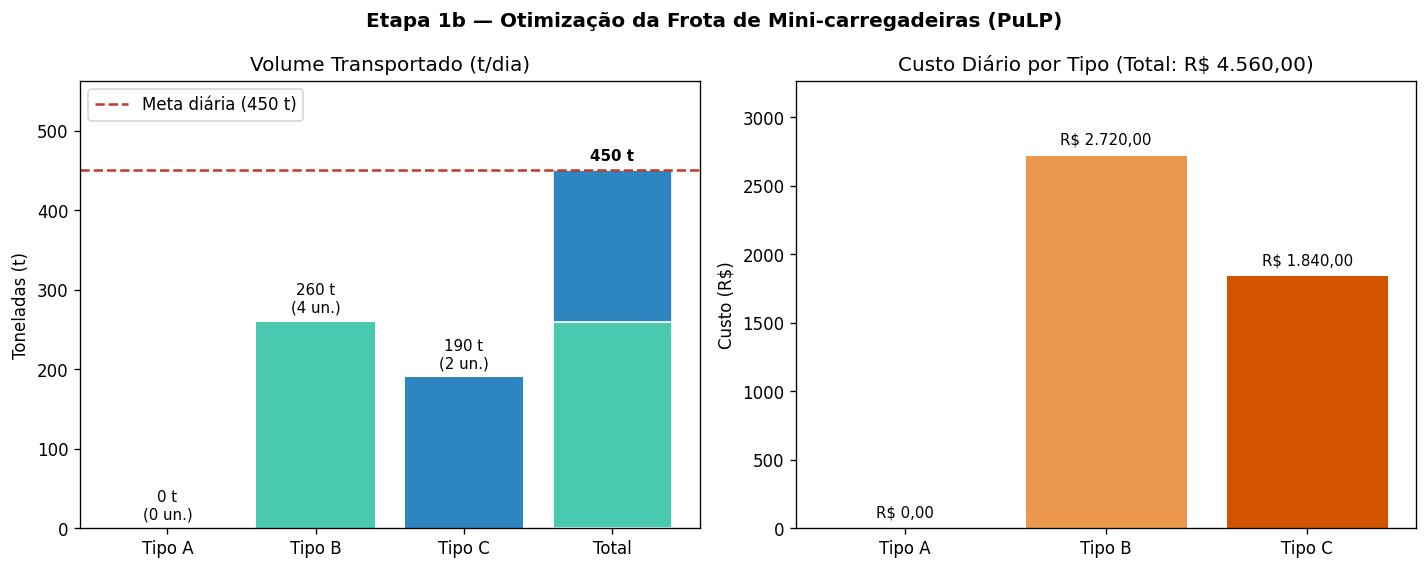

In [3]:
# ==============================================================================
# ETAPA 1b: ALOCAÇÃO ÓTIMA DE MINI-CARREGADEIRAS COM PULP (PL INTEIRA)
# ==============================================================================

# Premissas operacionais adotadas para o canteiro Torre Europarque:
# - Tipo A (Compacta):        40 t/dia | R$ 450,00/dia | Disponibilidade: 6 unid.
# - Tipo B (Média):           65 t/dia | R$ 680,00/dia | Disponibilidade: 6 unid.
# - Tipo C (Alta Capacidade): 95 t/dia | R$ 920,00/dia | Disponibilidade: 4 unid.
# - Demanda mínima diária:    450 toneladas de argamassa
# - Limite de tráfego no pátio: máximo de 10 equipamentos operando simultaneamente

dados_frota = {
    "A": {"capacidade": 40, "custo": 450, "max_disp": 6},
    "B": {"capacidade": 65, "custo": 680, "max_disp": 6},
    "C": {"capacidade": 95, "custo": 920, "max_disp": 4},
}
demanda_minima = 450

def brl(valor):
    """Formata valores no padrão monetário brasileiro (R$ 1.234,56)."""
    return f"R$ {valor:,.2f}".replace(",", "X").replace(".", ",").replace("X", ".")
limite_patio = 10

# 1. Criação do modelo de minimização
modelo = pulp.LpProblem("Alocacao_MiniCarregadeiras_Europarque", pulp.LpMinimize)

# 2. Variáveis de decisão (quantidade inteira de equipamentos alocados)
x = {
    tipo: pulp.LpVariable(f"Qtd_Tipo_{tipo}", lowBound=0, upBound=info["max_disp"], cat="Integer")
    for tipo, info in dados_frota.items()
}

# 3. Função Objetivo: Minimizar o custo operacional diário (R$)
modelo += pulp.lpSum(dados_frota[t]["custo"] * x[t] for t in dados_frota), "Custo_Total_Diario"

# 4. Restrições
# 4.1 Atender no mínimo 450 toneladas/dia
modelo += (
    pulp.lpSum(dados_frota[t]["capacidade"] * x[t] for t in dados_frota) >= demanda_minima,
    "Demanda_Minima_Argamassa"
)
# 4.2 Limite físico de circulação simultânea no canteiro
modelo += (
    pulp.lpSum(x[t] for t in dados_frota) <= limite_patio,
    "Limite_Maximo_Equipamentos"
)

# 5. Resolução
status = modelo.solve(pulp.PULP_CBC_CMD(msg=False))

print(f"Status da Solução: {pulp.LpStatus[status]}")
assert pulp.LpStatus[status] == "Optimal", "O modelo não encontrou solução ótima — revise as premissas."
resumo_pl = []
for t in dados_frota:
    qtd = int(round(x[t].varValue))  # round evita truncar 3.9999 para 3
    ton = qtd * dados_frota[t]["capacidade"]
    custo = qtd * dados_frota[t]["custo"]
    resumo_pl.append({"Tipo": f"Mini-carregadeira {t}", "Alocadas": qtd, "Capacidade (t)": ton, "Custo (R$)": custo})

df_pl = pd.DataFrame(resumo_pl)
display(df_pl)

ton_total = df_pl["Capacidade (t)"].sum()
custo_total_pl = pulp.value(modelo.objective)
print(f"\nTotal Transportado: {ton_total} t/dia (Meta: >= {demanda_minima} t/dia)")
print(f"Custo Operacional Ótimo: {brl(custo_total_pl)}/dia")
print(f"Custo por tonelada: {brl(custo_total_pl / ton_total)}/t")

# 6. Gráfico de alocação e custo
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

# Gráfico 1: volume por tipo + total empilhado comparado à meta
cores_tipo = ["#5DADE2", "#48C9B0", "#2E86C1"]
rotulos = [f"Tipo {t}" for t in dados_frota]
axes[0].bar(rotulos, df_pl["Capacidade (t)"], color=cores_tipo)
base = 0
for cor, v in zip(cores_tipo, df_pl["Capacidade (t)"]):
    axes[0].bar("Total", v, bottom=base, color=cor, edgecolor="white")
    base += v
axes[0].axhline(demanda_minima, color="#C0392B", linestyle="--", label=f"Meta diária ({demanda_minima} t)")
for i, (v, q) in enumerate(zip(df_pl["Capacidade (t)"], df_pl["Alocadas"])):
    axes[0].text(i, v + 12, f"{v} t\n({q} un.)", ha="center", fontsize=9)
axes[0].text(len(rotulos), ton_total + 12, f"{ton_total} t", ha="center", fontsize=9, fontweight="bold")
axes[0].set_ylim(0, max(ton_total, demanda_minima) * 1.25)
axes[0].set_title("Volume Transportado (t/dia)")
axes[0].set_ylabel("Toneladas (t)")
axes[0].legend(loc="upper left")

# Gráfico 2: custo diário por tipo
axes[1].bar(rotulos, df_pl["Custo (R$)"], color=["#F5B041", "#EB984E", "#D35400"])
for i, v in enumerate(df_pl["Custo (R$)"]):
    axes[1].text(i, v + df_pl["Custo (R$)"].max() * 0.03, brl(v), ha="center", fontsize=9)
axes[1].set_ylim(0, df_pl["Custo (R$)"].max() * 1.2)
axes[1].set_title(f"Custo Diário por Tipo (Total: {brl(custo_total_pl)})")
axes[1].set_ylabel("Custo (R$)")

plt.suptitle("Etapa 1b — Otimização da Frota de Mini-carregadeiras (PuLP)", fontweight="bold")
plt.tight_layout()
plt.savefig("outputs/graficos/etapa1b_pulp_frota.png", dpi=300)
plt.show()

**Análise dos resultados (1b)**
- Solução **ótima**: **4 mini-carregadeiras do tipo B e 2 do tipo C** (nenhuma do tipo A), transportando exatamente **450 t/dia** a um custo de **R$ 4.560,00/dia** (≈ R$ 10,13 por tonelada).
- Custo por tonelada de cada tipo: A = R$ 11,25/t, B = R$ 10,46/t, C = R$ 9,68/t. O tipo C é o mais eficiente, mas usar apenas ele não compensa: 4 unidades do tipo C entregam 380 t, e completar a meta com 2 do tipo A custaria R$ 4.580,00. A combinação B + C atinge a meta **sem sobra de capacidade**, e por isso é a de menor custo.
- As restrições de disponibilidade e de limite do pátio (6 equipamentos de 10 permitidos) **não ficaram ativas**. A restrição que define a solução é a demanda mínima.
- Como os parâmetros são premissas do grupo, o modelo deve ser reexecutado com os custos e capacidades reais da construtora antes de qualquer decisão de contratação.

## Etapa 2 — Otimização de Rotas (VRP) e Simulação de Eventos Discretos

### 2a — Algoritmo Genético para VRP com DEAP

In [5]:
# ==============================================================================
# ETAPA 2a - ALGORITMO GENÉTICO PARA VRP COM DEAP
# ==============================================================================

# Reinicia as sementes (outras células alteram o estado do gerador aleatório)
random.seed(SEED)
np.random.seed(SEED)

### 2b — Simulação de Concretagem com SimPy (Betoneira M1 → Bomba M2)
Linha em série com dois recursos de capacidade 1: a **Betoneira M1** (preparo, média de 5 min) e a **Bomba M2** (bombeamento, média de 7 min), ambos com tempos exponenciais, durante **300 min**. O enunciado não define o ritmo de chegada das demandas de carga: o grupo adotou **intervalo exponencial com média de 8 min**, maior que o tempo do recurso mais lento, para que o sistema seja estável. São executadas **30 réplicas** independentes, e os resultados são reportados como média ± desvio padrão.

,Média (30 réplicas),Desvio Padrão
Cargas_Processadas,34.00,4.50
Fila_Media_M1_min,7.22,5.50
Fila_Media_M2_min,15.26,10.48
Utilizacao_M1_%,65.10,12.65
Utilizacao_M2_%,76.50,12.67



Utilização média: M1 = 65.1% | M2 = 76.5%
Fila média:       M1 = 7.2 min | M2 = 15.3 min
>>> GARGALO IDENTIFICADO NA LINHA: Bomba de Concreto M2


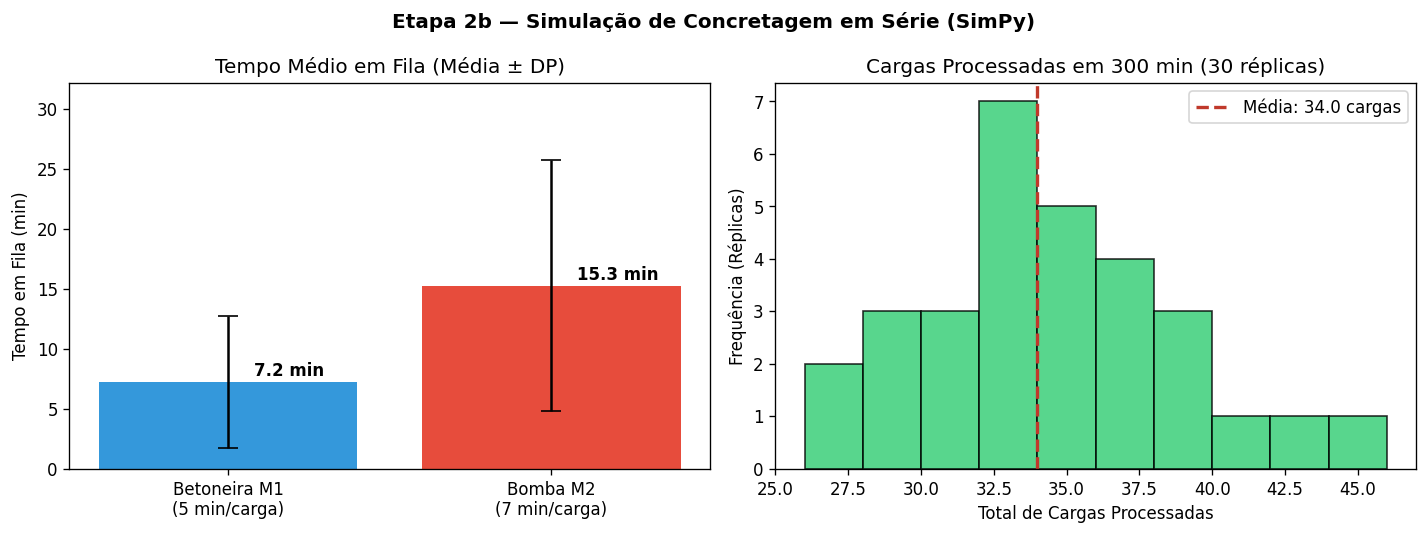

In [6]:
# ==============================================================================
# ETAPA 2b: SIMULAÇÃO DE CONCRETAGEM EM SÉRIE COM SIMPY (M1 -> M2)
# ==============================================================================

TEMPO_SIMULACAO = 300.0   # minutos (5 horas de operação contínua)
MEDIA_CHEGADA   = 8.0     # intervalo médio entre demandas de carga (min)
                          # premissa do grupo: maior que o serviço mais lento (7 min),
                          # para o sistema ser estável (com 5 min, a M1 opera com ρ = 1
                          # e as duas filas crescem sem limite, mascarando o gargalo)
MEDIA_M1        = 5.0     # tempo médio de preparo na Betoneira M1 (min)
MEDIA_M2        = 7.0     # tempo médio de bombeamento na Bomba M2 (min)
NUM_REPLICAS    = 30      # número de réplicas independentes

def executar_replica(seed):
    random.seed(seed)
    env = simpy.Environment()
    m1 = simpy.Resource(env, capacity=1)
    m2 = simpy.Resource(env, capacity=1)

    filas_m1, filas_m2 = [], []
    tempo_uso_m1, tempo_uso_m2 = 0.0, 0.0
    cargas_processadas = 0

    def processo_carga(env):
        nonlocal tempo_uso_m1, tempo_uso_m2, cargas_processadas

        # --- Estágio 1: Betoneira M1 ---
        chegada_m1 = env.now
        with m1.request() as req1:
            yield req1
            filas_m1.append(env.now - chegada_m1)
            duracao_m1 = random.expovariate(1.0 / MEDIA_M1)
            yield env.timeout(duracao_m1)
            tempo_uso_m1 += duracao_m1

        # --- Estágio 2: Bomba de Concreto M2 ---
        chegada_m2 = env.now
        with m2.request() as req2:
            yield req2
            filas_m2.append(env.now - chegada_m2)
            duracao_m2 = random.expovariate(1.0 / MEDIA_M2)
            yield env.timeout(duracao_m2)
            tempo_uso_m2 += duracao_m2

        cargas_processadas += 1

    def gerador_cargas(env):
        while True:
            env.process(processo_carga(env))
            yield env.timeout(random.expovariate(1.0 / MEDIA_CHEGADA))

    env.process(gerador_cargas(env))
    env.run(until=TEMPO_SIMULACAO)

    return {
        "Replica": seed - SEED + 1,
        "Cargas_Processadas": cargas_processadas,
        "Fila_Media_M1_min": np.mean(filas_m1) if filas_m1 else 0.0,
        "Fila_Media_M2_min": np.mean(filas_m2) if filas_m2 else 0.0,
        "Utilizacao_M1_%": min(100.0, (tempo_uso_m1 / TEMPO_SIMULACAO) * 100),
        "Utilizacao_M2_%": min(100.0, (tempo_uso_m2 / TEMPO_SIMULACAO) * 100),
    }

# Executa as 30 réplicas com seeds reprodutíveis (SEED, SEED+1, ...)
resultados_simpy = [executar_replica(SEED + i) for i in range(NUM_REPLICAS)]
df_simpy = pd.DataFrame(resultados_simpy)

# Estatísticas consolidadas
resumo_simpy = df_simpy.drop(columns=["Replica"]).agg(["mean", "std"]).T
resumo_simpy.columns = ["Média (30 réplicas)", "Desvio Padrão"]
display(resumo_simpy.round(2))

# Gargalo: recurso com maior utilização média, confirmado pela maior fila média
util_m1, util_m2 = df_simpy["Utilizacao_M1_%"].mean(), df_simpy["Utilizacao_M2_%"].mean()
fila_m1, fila_m2 = df_simpy["Fila_Media_M1_min"].mean(), df_simpy["Fila_Media_M2_min"].mean()
gargalo = "Bomba de Concreto M2" if util_m2 > util_m1 else "Betoneira M1"
confirmado = (util_m2 > util_m1) == (fila_m2 > fila_m1)
print(f"\nUtilização média: M1 = {util_m1:.1f}% | M2 = {util_m2:.1f}%")
print(f"Fila média:       M1 = {fila_m1:.1f} min | M2 = {fila_m2:.1f} min")
print(f">>> GARGALO IDENTIFICADO NA LINHA: {gargalo}"
      + ("" if confirmado else " (atenção: fila e utilização apontam recursos diferentes)"))

# Restaura a semente global (executar_replica altera o estado do gerador)
random.seed(SEED)

# Gráficos comparativos
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Gráfico 1: Comparação do Tempo Médio em Fila (M1 vs M2)
medias_fila = [df_simpy["Fila_Media_M1_min"].mean(), df_simpy["Fila_Media_M2_min"].mean()]
stds_fila   = [df_simpy["Fila_Media_M1_min"].std(),  df_simpy["Fila_Media_M2_min"].std()]
axes[0].bar(["Betoneira M1\n(5 min/carga)", "Bomba M2\n(7 min/carga)"], medias_fila,
            yerr=stds_fila, capsize=6, color=["#3498DB", "#E74C3C"])
axes[0].set_title("Tempo Médio em Fila (Média ± DP)")
axes[0].set_ylim(0, max(m + d for m, d in zip(medias_fila, stds_fila)) * 1.25)
axes[0].set_ylabel("Tempo em Fila (min)")
for i, v in enumerate(medias_fila):
    axes[0].text(i + 0.08, v + 0.5, f"{v:.1f} min", ha="left", fontweight="bold")

# Gráfico 2: Distribuição de Cargas Processadas nas 30 réplicas
axes[1].hist(df_simpy["Cargas_Processadas"], bins=10, color="#2ECC71", edgecolor="black", alpha=0.8)
media_cargas = df_simpy["Cargas_Processadas"].mean()
axes[1].axvline(media_cargas, color="#C0392B", linestyle="--", lw=2, label=f"Média: {media_cargas:.1f} cargas")
axes[1].set_title(f"Cargas Processadas em {int(TEMPO_SIMULACAO)} min ({NUM_REPLICAS} réplicas)")
axes[1].set_xlabel("Total de Cargas Processadas")
axes[1].set_ylabel("Frequência (Réplicas)")
axes[1].legend()

plt.suptitle("Etapa 2b — Simulação de Concretagem em Série (SimPy)", fontweight="bold")
plt.tight_layout()
plt.savefig("outputs/graficos/etapa2b_simpy_gargalo.png", dpi=300)
plt.show()

**Análise dos resultados (2b)**
- Em 300 min, a linha processou em média **34,0 ± 4,5 cargas** nas 30 réplicas.
- A **Bomba de Concreto M2** é o **gargalo**: ela tem a maior utilização (**76,5%** contra **65,1%** da Betoneira M1) e o maior tempo médio em fila (**15,3 min** contra **7,2 min**). Isso é coerente com a teoria: a M2 é o recurso mais lento (7 min contra 5 min), e a capacidade máxima dela, de ≈ 300/7 ≈ 43 cargas, limita a vazão da linha inteira.
- O desvio padrão elevado mostra a alta variabilidade causada pelos tempos exponenciais. Por isso foram usadas várias réplicas, em vez de uma execução única.
- **Recomendação:** aumentar a capacidade da etapa de bombeamento (uma segunda bomba ou redução do tempo de bombeamento) traz mais ganho do que investir na betoneira. Melhorar a M1 só aumentaria a fila na frente da M2.
- **Limitações:** a média de fila considera apenas as cargas que chegaram a ser atendidas. Cargas ainda esperando no minuto 300 não entram na conta, o que subestima levemente a fila da M2. A utilização também conta apenas os serviços concluídos dentro do horizonte.

## Etapa 3 — Ontologia RDF/OWL e Consultas SPARQL

### 3a — Ontologia RDF/OWL em rdflib
O conhecimento de suprimentos do canteiro é modelado como um **grafo de conhecimento**, formado por triplas (sujeito, predicado, objeto). A **ontologia** define as classes `Projeto`, `Insumo` e `Fornecedor` (mutuamente disjuntas) e a subclasse `MaterialAltaResistencia` de `Insumo`. As relações são `utiliza` (Projeto → Insumo) e `fornece` (Fornecedor → Insumo), ambas com a inversa declarada por `owl:inverseOf`. Os atributos são `codigoSINAPI`, `descricaoSINAPI`, `unidade`, `resistenciaCaracteristicaMPa` e `homologado`.

**Origem dos dados.** Os códigos e as descrições dos quatro insumos (34494 — concreto C30, 34 — aço CA-50 de 10,0 mm, 43055 — aço CA-50 de 12,5 ou 16,0 mm e 371 — argamassa multiuso) são da tabela **SINAPI**, conferidos em fontes públicas que reproduzem a tabela (referência 05/2026); antes de qualquer uso em orçamento, devem ser validados na tabela oficial da Caixa. Os preços não foram incluídos, pois variam por estado e por mês, e o **CUB** não foi modelado como insumo, por ser um índice de custo por m² de cada padrão de obra e não um item com código. Os **fornecedores** (nomes fictícios), o projeto "Residencial Jardim das Acácias" e todos os vínculos projeto–insumo–fornecedor são **premissas ilustrativas do grupo**, pois o enunciado não informa a lista de fornecedores homologados. O critério de "alta resistência" também é do grupo: concreto com fck ≥ 30 MPa e aço CA-50 (fyk = 500 MPa).

In [7]:
# ==============================================================================
# ETAPA 3 - ONTOLOGIA RDF/OWL E CONSULTAS SPARQL
# ==============================================================================

# ------------------------------------------------------------------------------
# 3a. Construção da ontologia RDF/OWL com rdflib
# ------------------------------------------------------------------------------
# Premissas (ver texto acima da célula):
# - Os CÓDIGOS e as DESCRIÇÕES dos insumos são os da tabela SINAPI (confira o
#   mês de referência na tabela oficial da Caixa antes de usar em orçamento).
# - Projetos "Torre Europarque" (enunciado) e "Residencial Jardim das Acácias"
#   (fictício), e TODOS os fornecedores e vínculos são PREMISSAS ILUSTRATIVAS
#   do grupo: o enunciado não traz a lista de fornecedores homologados.
# - Critério de "alta resistência" adotado pelo grupo: concreto com fck >= 30 MPa
#   e aço CA-50 (fyk = 500 MPa).

import textwrap

BASE = "http://example.org/aps2/torre-europarque#"
TE = Namespace(BASE)
ONTOLOGIA = URIRef(BASE[:-1])

g = Graph()
g.bind("te", TE)

# ------------------------------------------------------------------------------
# 1. TBox (esquema): classes, propriedades e axiomas
# ------------------------------------------------------------------------------
g.add((ONTOLOGIA, RDF.type, OWL.Ontology))
g.add((ONTOLOGIA, RDFS.label,
       Literal("Rastreabilidade de suprimentos do canteiro Torre Europarque", lang="pt")))

classes = {  # nome: (rótulo, comentário)
    "Projeto": ("Projeto", "Obra ou empreendimento que consome insumos."),
    "Insumo": ("Insumo", "Material de construção identificado por um código da tabela SINAPI."),
    "Fornecedor": ("Fornecedor", "Empresa que fornece insumos às obras."),
    "MaterialAltaResistencia": ("Material de alta resistência",
                                "Insumo estrutural de alta resistência: concreto com fck >= 30 MPa e aço CA-50."),
}
for nome, (rotulo, comentario) in classes.items():
    g.add((TE[nome], RDF.type, OWL.Class))
    g.add((TE[nome], RDFS.label, Literal(rotulo, lang="pt")))
    g.add((TE[nome], RDFS.comment, Literal(comentario, lang="pt")))

# Hierarquia: todo material de alta resistência é um insumo
g.add((TE.MaterialAltaResistencia, RDFS.subClassOf, TE.Insumo))

# As três classes de topo não se sobrepõem
for a, b in [("Projeto", "Insumo"), ("Projeto", "Fornecedor"), ("Insumo", "Fornecedor")]:
    g.add((TE[a], OWL.disjointWith, TE[b]))

# Propriedades de objeto (relações) e suas inversas
propriedades_objeto = [  # (nome, domínio, imagem, inversa)
    ("utiliza", "Projeto", "Insumo", "utilizadoEm"),
    ("fornece", "Fornecedor", "Insumo", "fornecidoPor"),
]
for nome, dominio, imagem, inversa in propriedades_objeto:
    g.add((TE[nome], RDF.type, OWL.ObjectProperty))
    g.add((TE[nome], RDFS.domain, TE[dominio]))
    g.add((TE[nome], RDFS.range, TE[imagem]))
    g.add((TE[inversa], RDF.type, OWL.ObjectProperty))
    g.add((TE[inversa], OWL.inverseOf, TE[nome]))
    g.add((TE[inversa], RDFS.domain, TE[imagem]))
    g.add((TE[inversa], RDFS.range, TE[dominio]))

# Propriedades de dados (atributos)
propriedades_dado = [  # (nome, domínio, tipo XSD, comentário)
    ("codigoSINAPI", "Insumo", XSD.string, "Código do insumo na tabela SINAPI."),
    ("descricaoSINAPI", "Insumo", XSD.string, "Descrição oficial do insumo na tabela SINAPI."),
    ("unidade", "Insumo", XSD.string, "Unidade de medida do insumo na tabela SINAPI."),
    ("resistenciaCaracteristicaMPa", "Insumo", XSD.integer,
     "fck (concreto) ou fyk (aço), em MPa."),
    ("homologado", "Fornecedor", XSD.boolean, "Indica se o fornecedor está homologado pela construtora."),
]
for nome, dominio, tipo, comentario in propriedades_dado:
    g.add((TE[nome], RDF.type, OWL.DatatypeProperty))
    g.add((TE[nome], RDFS.domain, TE[dominio]))
    g.add((TE[nome], RDFS.range, tipo))
    g.add((TE[nome], RDFS.comment, Literal(comentario, lang="pt")))

# ------------------------------------------------------------------------------
# 2. ABox (instâncias): insumos SINAPI, projetos e fornecedores
# ------------------------------------------------------------------------------
INSUMOS = {  # id: dados do insumo (código e descrição conforme tabela SINAPI)
    "ConcretoFck30": dict(
        rotulo="Concreto usinado bombeável FCK 30 (C30)", codigo="34494", unidade="M3", mpa=30, alta=True,
        descricao="CONCRETO USINADO BOMBEAVEL, CLASSE DE RESISTENCIA C30, COM BRITA 0 E 1, "
                  "SLUMP = 100 +/- 20 MM, EXCLUI SERVICO DE BOMBEAMENTO (NBR 8953)"),
    "AcoCA50_10mm": dict(
        rotulo="Aço CA-50, 10,0 mm (vergalhão)", codigo="34", unidade="KG", mpa=500, alta=True,
        descricao="ACO CA-50, 10,0 MM, VERGALHAO"),
    "ArgamassaMultiuso": dict(
        rotulo="Argamassa industrializada multiuso", codigo="371", unidade="KG", mpa=None, alta=False,
        descricao="ARGAMASSA INDUSTRIALIZADA MULTIUSO, PARA REVESTIMENTO INTERNO E EXTERNO "
                  "E ASSENTAMENTO DE BLOCOS DIVERSOS"),
    "AcoCA50_12_5e16mm": dict(
        rotulo="Aço CA-50, 12,5 ou 16,0 mm (vergalhão)", codigo="43055", unidade="KG", mpa=500, alta=True,
        descricao="ACO CA-50, 12,5 MM OU 16,0 MM, VERGALHAO"),
}

PROJETOS = {  # id: (rótulo, insumos utilizados)
    "TorreEuroparque": ("Torre Europarque",
                        ["ConcretoFck30", "AcoCA50_10mm", "ArgamassaMultiuso"]),
    "JardimDasAcacias": ("Residencial Jardim das Acácias",
                         ["ArgamassaMultiuso", "AcoCA50_12_5e16mm"]),
}

FORNECEDORES = {  # id: (rótulo, homologado?, insumos fornecidos)
    "ConcreteiraAlfa": ("Concreteira Alfa Ltda.", True, ["ConcretoFck30"]),
    "ConcreteiraDelta": ("Concreteira Delta Ltda.", False, ["ConcretoFck30"]),
    "SiderurgicaBeta": ("Siderúrgica Beta S.A.", True, ["AcoCA50_10mm"]),
    "DistribuidoraEpsilon": ("Distribuidora Épsilon Ltda.", True, ["AcoCA50_10mm", "ArgamassaMultiuso"]),
    "ArgamassasGama": ("Argamassas Gama Ltda.", True, ["ArgamassaMultiuso"]),
    "MetalurgicaZeta": ("Metalúrgica Zeta Ltda.", False, ["AcoCA50_12_5e16mm"]),
}

for id_insumo, d in INSUMOS.items():
    uri = TE[id_insumo]
    # A classe mais específica é afirmada; "Insumo" será inferido pela hierarquia
    g.add((uri, RDF.type, TE.MaterialAltaResistencia if d["alta"] else TE.Insumo))
    g.add((uri, RDFS.label, Literal(d["rotulo"], lang="pt")))
    g.add((uri, TE.codigoSINAPI, Literal(d["codigo"])))
    g.add((uri, TE.descricaoSINAPI, Literal(d["descricao"])))
    g.add((uri, TE.unidade, Literal(d["unidade"])))
    if d["mpa"] is not None:
        g.add((uri, TE.resistenciaCaracteristicaMPa, Literal(d["mpa"], datatype=XSD.integer)))

for id_projeto, (rotulo, usados) in PROJETOS.items():
    g.add((TE[id_projeto], RDF.type, TE.Projeto))
    g.add((TE[id_projeto], RDFS.label, Literal(rotulo, lang="pt")))
    for id_insumo in usados:
        g.add((TE[id_projeto], TE.utiliza, TE[id_insumo]))

for id_forn, (rotulo, homologado, fornecidos) in FORNECEDORES.items():
    g.add((TE[id_forn], RDF.type, TE.Fornecedor))
    g.add((TE[id_forn], RDFS.label, Literal(rotulo, lang="pt")))
    g.add((TE[id_forn], RDFS.comment,
           Literal("Fornecedor fictício (premissa do grupo).", lang="pt")))
    g.add((TE[id_forn], TE.homologado, Literal(homologado, datatype=XSD.boolean)))
    for id_insumo in fornecidos:
        g.add((TE[id_forn], TE.fornece, TE[id_insumo]))

# ------------------------------------------------------------------------------
# 3. Verificações, resumo e exportação em Turtle
# ------------------------------------------------------------------------------
assert (TE.MaterialAltaResistencia, RDFS.subClassOf, TE.Insumo) in g

resumo = pd.DataFrame({
    "Elemento": ["Triplas no grafo", "Classes (owl:Class)", "Propriedades de objeto",
                 "Propriedades de dados", "Insumos SINAPI", "Projetos", "Fornecedores"],
    "Quantidade": [len(g),
                   len(set(g.subjects(RDF.type, OWL.Class))),
                   len(set(g.subjects(RDF.type, OWL.ObjectProperty))),
                   len(set(g.subjects(RDF.type, OWL.DatatypeProperty))),
                   len(INSUMOS), len(PROJETOS), len(FORNECEDORES)],
})
display(resumo)

# Trecho do grafo em Turtle: o concreto FCK 30 e um fornecedor
trecho = Graph()
trecho.bind("te", TE)
for alvo in (TE.ConcretoFck30, TE.ConcreteiraAlfa):
    for tripla in g.triples((alvo, None, None)):
        trecho.add(tripla)
print(trecho.serialize(format="turtle"))

g.serialize(destination="outputs/tabelas/etapa3_ontologia.ttl", format="turtle")
print("Ontologia completa exportada em outputs/tabelas/etapa3_ontologia.ttl")

,Elemento,Quantidade
0,Triplas no grafo,115
1,Classes (owl:Class),4
2,Propriedades de objeto,4
3,Propriedades de dados,5
4,Insumos SINAPI,4
5,Projetos,2
6,Fornecedores,6


@prefix rdfs: <http://www.w3.org/2000/01/rdf-schema#> .
@prefix te: <http://example.org/aps2/torre-europarque#> .
@prefix xsd: <http://www.w3.org/2001/XMLSchema#> .

te:ConcreteiraAlfa a te:Fornecedor ;
    rdfs:label "Concreteira Alfa Ltda."@pt ;
    te:fornece te:ConcretoFck30 ;
    te:homologado true ;
    rdfs:comment "Fornecedor fictício (premissa do grupo)."@pt .

te:ConcretoFck30 a te:MaterialAltaResistencia ;
    rdfs:label "Concreto usinado bombeável FCK 30 (C30)"@pt ;
    te:codigoSINAPI "34494" ;
    te:descricaoSINAPI "CONCRETO USINADO BOMBEAVEL, CLASSE DE RESISTENCIA C30, COM BRITA 0 E 1, SLUMP = 100 +/- 20 MM, EXCLUI SERVICO DE BOMBEAMENTO (NBR 8953)" ;
    te:resistenciaCaracteristicaMPa 30 ;
    te:unidade "M3" .


Ontologia completa exportada em outputs/tabelas/etapa3_ontologia.ttl


**Análise dos resultados (3a)**
- O grafo tem **115 triplas**: 4 classes, 4 propriedades de objeto (2 relações e suas 2 inversas), 5 propriedades de dados, 4 insumos, 2 projetos e 6 fornecedores. As triplas completas são exportadas em Turtle (`outputs/tabelas/etapa3_ontologia.ttl`).
- Os três insumos de alta resistência são afirmados **apenas** como `MaterialAltaResistencia`. A condição de `Insumo` é consequência da hierarquia (`rdfs:subClassOf`) e não é repetida nos dados, o que evita redundância, mas exige que as consultas percorram a hierarquia (consulta 3).
- O **rdflib não faz raciocínio OWL**. As declarações `owl:inverseOf`, `owl:disjointWith`, `rdfs:domain` e `rdfs:range` documentam o modelo, mas não são verificadas nem materializadas: só `utiliza` e `fornece` contêm dados. Para inferência automática seria necessário um raciocinador (por exemplo, o pacote `owlrl`) ou um triplestore com suporte a OWL.
- **Limitações:** os fornecedores e vínculos são fictícios. Pela NBR 8953, o concreto C30 pertence ao grupo I (C20 a C50), e o termo "alta resistência" costuma ser reservado a classes acima de C50; o C30 foi tratado como alta resistência por critério adotado pelo grupo para atender ao enunciado, e esse critério deve ser revisto com a construtora.

### 3b — Consultas SPARQL
Quatro consultas sobre o grafo: **(1)** a pedida no enunciado, com os fornecedores homologados dos materiais de alta resistência usados na Torre Europarque; **(2)** a cobertura de fornecedores homologados por insumo de cada projeto, com `OPTIONAL`, `COUNT` e `GROUP BY`; **(3)** a listagem de todos os insumos pela hierarquia de classes (`rdfs:subClassOf*`), comparada a uma consulta sem hierarquia; e **(4)** uma consulta `ASK` que verifica se algum insumo do projeto está sem fornecedor homologado. Os resultados são exibidos em tabelas e exportados em CSV.

Consulta 1 - Fornecedores homologados de materiais de alta resistência (Torre Europarque)


,Código SINAPI,Material de alta resistência,Fornecedor homologado
0,34,"Aço CA-50, 10,0 mm (vergalhão)",Distribuidora Épsilon Ltda.
1,34,"Aço CA-50, 10,0 mm (vergalhão)",Siderúrgica Beta S.A.
2,34494,Concreto usinado bombeável FCK 30 (C30),Concreteira Alfa Ltda.



Consulta 2 - Cobertura de fornecedores homologados por insumo de cada projeto


,Projeto,Código SINAPI,Insumo,Fornecedores homologados
0,Residencial Jardim das Acácias,371,Argamassa industrializada multiuso,2
1,Residencial Jardim das Acácias,43055,"Aço CA-50, 12,5 ou 16,0 mm (vergalhão)",0
2,Torre Europarque,371,Argamassa industrializada multiuso,2
3,Torre Europarque,34,"Aço CA-50, 10,0 mm (vergalhão)",2
4,Torre Europarque,34494,Concreto usinado bombeável FCK 30 (C30),1



Consulta 3 - Insumos considerando a hierarquia de classes
Sem a hierarquia (rdf:type te:Insumo): 1 instância(s) | com rdfs:subClassOf*: 4 instância(s)


,Código SINAPI,Insumo,Classe afirmada
0,34,"Aço CA-50, 10,0 mm (vergalhão)",te:MaterialAltaResistencia
1,34494,Concreto usinado bombeável FCK 30 (C30),te:MaterialAltaResistencia
2,371,Argamassa industrializada multiuso,te:Insumo
3,43055,"Aço CA-50, 12,5 ou 16,0 mm (vergalhão)",te:MaterialAltaResistencia



Consulta 4 (ASK) - Lacunas de homologação por projeto


,Projeto,Há insumo sem fornecedor homologado?
0,Torre Europarque,Não
1,Residencial Jardim das Acácias,Sim


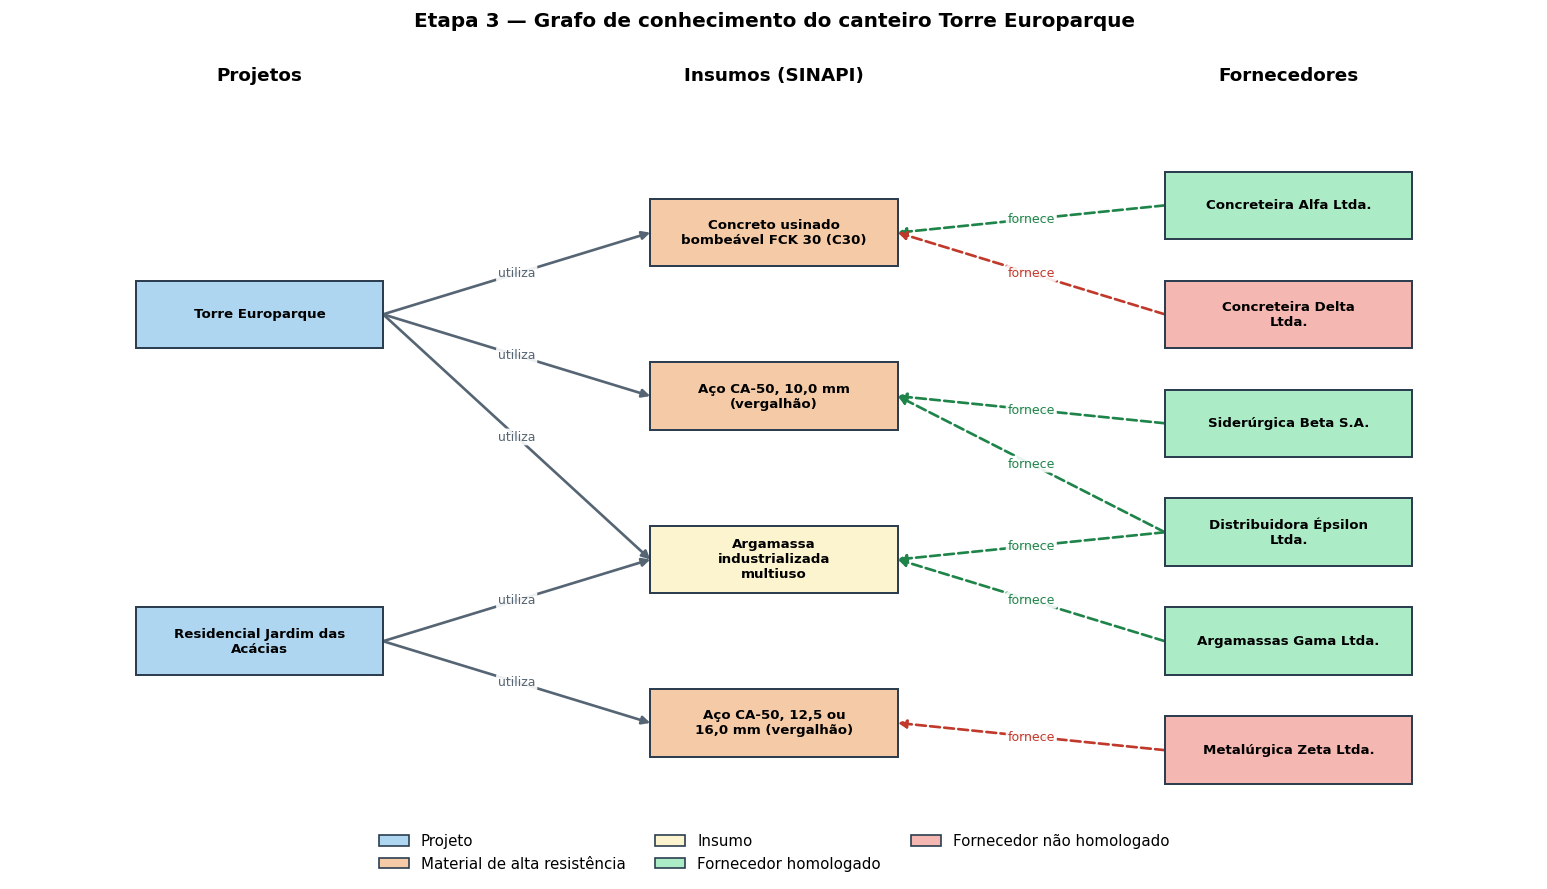

In [8]:
# ------------------------------------------------------------------------------
# 3b. Consultas SPARQL sobre o grafo de conhecimento
# ------------------------------------------------------------------------------
from matplotlib.patches import Patch

PREFIXOS = """
PREFIX te:   <http://example.org/aps2/torre-europarque#>
PREFIX rdf:  <http://www.w3.org/1999/02/22-rdf-syntax-ns#>
PREFIX rdfs: <http://www.w3.org/2000/01/rdf-schema#>
"""

def valor(termo):
    """Converte um termo RDF em valor simples para exibir na tabela."""
    if termo is None:                       # variável não ligada (OPTIONAL)
        return ""
    if isinstance(termo, Literal):
        return termo.toPython() if termo.datatype is not None else str(termo)
    return str(termo).replace(BASE, "te:")  # URIs aparecem com o prefixo te:

def executar_sparql(consulta, colunas):
    """Executa uma consulta SELECT no grafo e devolve um DataFrame."""
    resultado = g.query(PREFIXOS + consulta)
    linhas = [[valor(termo) for termo in linha] for linha in resultado]
    return pd.DataFrame(linhas, columns=colunas)

# ------------------------------------------------------------------------------
# Consulta 1 (enunciado): fornecedores homologados de materiais de alta resistência
# usados na Torre Europarque
# ------------------------------------------------------------------------------
consulta_1 = """
SELECT ?codigo ?insumo ?fornecedor
WHERE {
  te:TorreEuroparque te:utiliza ?i .
  ?i rdf:type te:MaterialAltaResistencia ;
     te:codigoSINAPI ?codigo ;
     rdfs:label ?insumo .
  ?f te:fornece ?i ;
     te:homologado true ;
     rdfs:label ?fornecedor .
}
ORDER BY ?insumo ?fornecedor
"""
df_q1 = executar_sparql(consulta_1, ["Código SINAPI", "Material de alta resistência", "Fornecedor homologado"])
print("Consulta 1 - Fornecedores homologados de materiais de alta resistência (Torre Europarque)")
display(df_q1)
df_q1.to_csv("outputs/tabelas/etapa3_sparql_q1_fornecedores.csv", index=False)

# ------------------------------------------------------------------------------
# Consulta 2: rastreabilidade - cobertura de fornecedores homologados por insumo
# ------------------------------------------------------------------------------
consulta_2 = """
SELECT ?projeto ?codigo ?insumo (COUNT(DISTINCT ?f) AS ?qtd)
WHERE {
  ?p te:utiliza ?i ;
     rdfs:label ?projeto .
  ?i te:codigoSINAPI ?codigo ;
     rdfs:label ?insumo .
  OPTIONAL { ?f te:fornece ?i ; te:homologado true . }
}
GROUP BY ?projeto ?codigo ?insumo
ORDER BY ?projeto ?insumo
"""
df_q2 = executar_sparql(consulta_2, ["Projeto", "Código SINAPI", "Insumo", "Fornecedores homologados"])
print("\nConsulta 2 - Cobertura de fornecedores homologados por insumo de cada projeto")
display(df_q2)
df_q2.to_csv("outputs/tabelas/etapa3_sparql_q2_cobertura.csv", index=False)

# ------------------------------------------------------------------------------
# Consulta 3: hierarquia de classes (rdfs:subClassOf*) - todos os insumos
# ------------------------------------------------------------------------------
consulta_3_direta = """
SELECT ?i
WHERE { ?i rdf:type te:Insumo . }
"""
consulta_3 = """
SELECT ?codigo ?insumo ?classe
WHERE {
  ?i rdf:type ?classe ;
     te:codigoSINAPI ?codigo ;
     rdfs:label ?insumo .
  ?classe rdfs:subClassOf* te:Insumo .
}
ORDER BY ?codigo
"""
n_direto = len(g.query(PREFIXOS + consulta_3_direta))
df_q3 = executar_sparql(consulta_3, ["Código SINAPI", "Insumo", "Classe afirmada"])
print("\nConsulta 3 - Insumos considerando a hierarquia de classes")
print(f"Sem a hierarquia (rdf:type te:Insumo): {n_direto} instância(s) | "
      f"com rdfs:subClassOf*: {len(df_q3)} instância(s)")
display(df_q3)
df_q3.to_csv("outputs/tabelas/etapa3_sparql_q3_hierarquia.csv", index=False)

# ------------------------------------------------------------------------------
# Consulta 4 (ASK): algum insumo do projeto está sem fornecedor homologado?
# ------------------------------------------------------------------------------
consulta_4 = """
ASK {
  te:@PROJETO@ te:utiliza ?i .
  FILTER NOT EXISTS { ?f te:fornece ?i ; te:homologado true . }
}
"""
linhas_q4 = []
for id_projeto, (rotulo, _) in PROJETOS.items():
    lacuna = g.query(PREFIXOS + consulta_4.replace("@PROJETO@", id_projeto)).askAnswer
    linhas_q4.append({"Projeto": rotulo, "Há insumo sem fornecedor homologado?": "Sim" if lacuna else "Não"})
df_q4 = pd.DataFrame(linhas_q4)
print("\nConsulta 4 (ASK) - Lacunas de homologação por projeto")
display(df_q4)
df_q4.to_csv("outputs/tabelas/etapa3_sparql_q4_lacunas.csv", index=False)

# ------------------------------------------------------------------------------
# Gráfico: grafo de conhecimento (projetos -> insumos <- fornecedores)
# ------------------------------------------------------------------------------
def desenhar_grafo(nos, arestas, caminho):
    """nos: {id: (rótulo, grupo, coluna, linha)}; arestas: [(origem, destino, relação)]."""
    cores = {"Projeto": "#AED6F1", "Material de alta resistência": "#F5CBA7", "Insumo": "#FCF3CF",
             "Fornecedor homologado": "#ABEBC6", "Fornecedor não homologado": "#F5B7B1"}
    larg, alt, esp_x = 1.25, 0.62, 2.6
    n_linhas = {c: max(l for _, _, col, l in nos.values() if col == c) + 1 for c in (0, 1, 2)}
    altura_total = max(n_linhas.values())

    def centro(no):
        _, _, col, lin = nos[no]
        passo = altura_total / n_linhas[col]
        return col * esp_x, (altura_total - 1) - (lin + 0.5) * passo + 0.5

    fig, ax = plt.subplots(figsize=(13, 7.5))
    for origem, destino, relacao in arestas:
        (x0, y0), (x1, y1) = centro(origem), centro(destino)
        cor = "#566573"
        if relacao == "fornece":
            cor = "#1E8449" if nos[origem][1] == "Fornecedor homologado" else "#C0392B"
        lado = 1 if x1 > x0 else -1
        ax.annotate("", xy=(x1 - lado * larg / 2, y1), xytext=(x0 + lado * larg / 2, y0),
                    arrowprops=dict(arrowstyle="-|>", color=cor, lw=1.6,
                                    ls="--" if relacao == "fornece" else "-", shrinkA=0, shrinkB=0))
        ax.text((x0 + x1) / 2, (y0 + y1) / 2, relacao, fontsize=7.5, color=cor, ha="center",
                va="center", bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.9), zorder=4)
    for no, (rotulo, grupo, col, lin) in nos.items():
        x, y = centro(no)
        ax.add_patch(plt.Rectangle((x - larg / 2, y - alt / 2), larg, alt, facecolor=cores[grupo],
                                   edgecolor="#2C3E50", lw=1.2, zorder=5))
        ax.text(x, y, "\n".join(textwrap.wrap(rotulo, 22)), ha="center", va="center", fontsize=8,
                fontweight="bold", zorder=6)
    for col, titulo in enumerate(["Projetos", "Insumos (SINAPI)", "Fornecedores"]):
        ax.text(col * esp_x, altura_total + 0.15, titulo, ha="center", fontsize=11, fontweight="bold")
    ax.legend(handles=[Patch(fc=c, ec="#2C3E50", label=r) for r, c in cores.items()],
              loc="upper center", bbox_to_anchor=(0.5, -0.02), ncol=3, fontsize=9, frameon=False)
    ax.set_xlim(-larg, 2 * esp_x + larg)
    ax.set_ylim(-0.5, altura_total + 0.55)
    ax.axis("off")
    ax.set_title("Etapa 3 — Grafo de conhecimento do canteiro Torre Europarque", fontweight="bold")
    plt.tight_layout()
    plt.savefig(caminho, dpi=300)
    plt.show()

# Nós e arestas extraídos do grafo RDF (a ordem das linhas segue a ordem dos dicionários)
nos, arestas = {}, []
for i, id_projeto in enumerate(PROJETOS):
    nos[TE[id_projeto]] = (str(g.value(TE[id_projeto], RDFS.label)), "Projeto", 0, i)
for i, id_insumo in enumerate(INSUMOS):
    grupo = "Material de alta resistência" if (TE[id_insumo], RDF.type, TE.MaterialAltaResistencia) in g else "Insumo"
    nos[TE[id_insumo]] = (str(g.value(TE[id_insumo], RDFS.label)), grupo, 1, i)
for i, id_forn in enumerate(FORNECEDORES):
    homologado = g.value(TE[id_forn], TE.homologado).toPython()
    grupo = "Fornecedor homologado" if homologado else "Fornecedor não homologado"
    nos[TE[id_forn]] = (str(g.value(TE[id_forn], RDFS.label)), grupo, 2, i)
for s, _, o in g.triples((None, TE.utiliza, None)):
    arestas.append((s, o, "utiliza"))
for s, _, o in g.triples((None, TE.fornece, None)):
    arestas.append((s, o, "fornece"))

desenhar_grafo(nos, arestas, "outputs/graficos/etapa3_grafo_conhecimento.png")

**Análise dos resultados (3b)**
- **Consulta 1:** retornou **3 pares insumo–fornecedor**: o aço CA-50 de 10,0 mm (34) com a Distribuidora Épsilon e a Siderúrgica Beta, e o concreto C30 (34494) com a Concreteira Alfa. A Concreteira Delta, também fornecedora de C30, não aparece porque **não é homologada**. O aço de 12,5/16,0 mm (43055) não aparece porque não é usado na Torre Europarque, e a argamassa não é material de alta resistência.
- **Consulta 2:** na Torre Europarque, todos os insumos têm fornecedor homologado, mas o **concreto C30 depende de um único fornecedor** (Concreteira Alfa), ou seja, um ponto único de falha no abastecimento. No Residencial Jardim das Acácias, o aço 43055 tem **0** fornecedores homologados (o único fornecedor, a Metalúrgica Zeta, não é homologado), uma lacuna que o grafo torna visível.
- **Consulta 3:** sem considerar a hierarquia, `rdf:type te:Insumo` devolve apenas **1** instância (a argamassa); com `rdfs:subClassOf*`, devolve as **4**. Isso mostra o efeito da subclasse `MaterialAltaResistencia` e a necessidade de percorrer a hierarquia no rdflib.
- **Consulta 4 (ASK):** a Torre Europarque **não** tem insumo sem fornecedor homologado, e o Residencial Jardim das Acácias **tem**, o que concorda com a consulta 2.
- **Limitações:** os resultados dependem dos dados fictícios definidos em 3a e devem ser refeitos com os fornecedores reais da construtora. Com o grafo em memória do rdflib, o desempenho é adequado a este exemplo; para milhões de triplas seria preciso um triplestore dedicado (por exemplo, Apache Jena Fuseki ou GraphDB). Esta etapa não depende da semente aleatória (`SEED`), pois não há componente estocástico.

## Etapa 4 — Rede Neural MLP do Zero em NumPy (Forward Pass)

In [ ]:
## Etapa 4 — Rede Neural MLP do Zero em NumPy (Forward Pass)

In [ ]:
# ==============================================================================
# ETAPA 4 - REDE NEURAL MLP DO ZERO EM NUMPY
# ==============================================================================

# Reinicia a semente para pesos reprodutíveis
np.random.seed(SEED)

## Etapa 5 — Sistema de Inferência Fuzzy (Mamdani e Sugeno)


In [ ]:
# ==============================================================================
# ETAPA 5 - SISTEMA DE INFERÊNCIA FUZZY
# ==============================================================================